# Array 51745334 — which half of the stage-F cut is load-bearing at N=96?

Stage F (finding 55) measured the N=48 standing minimum at N=96 and it did not
transfer: the stripped cell `no_mlp L=16 d192` landed at `rho_50` **0.850**
against a paired control `full L=12 d256` at **0.676**, a gap of `+0.175` =
**1.47 s\*_96**. That comparison changed **two things at once** — the
architecture (MLP removed) *and* the shape (`L=12 d256` → `L=16 d192`) — so it
could not say which one cost the 1.47 bars.

Stage M completes the square. Two corners already existed; M bought the two
missing ones at three seeds each:

| corner | architecture | shape | what it isolates |
|---|---|---|---|
| **A** control | `full` | `L=12 d256` | the reference |
| **B** shape | `full` | `L=16 d192` | shape alone (`dSHAPE = B − A`) |
| **C** MLP | `no_mlp` | `L=12 d256` | the MLP cut alone (`dMLP = C − A`) |
| **D** stripped | `no_mlp` | `L=16 d192` | both, = stage F's arm |

**The registered hypotheses**, from `scripts/slurm/sudoku2_n96_cuthalf_M_2026-11-09.sbatch`
(commit `872f5d7`), with the bars frozen at registration — `rho_50` **0.117**,
`mean_solve` **0.1586**, `val_token_acc` **0.0079**, each the mean |max−min| over
the four multi-seed N=96 rungs that existed then:

* **M0 — the headline.** *Exactly one* of `|dMLP|`, `|dSHAPE|` exceeds
  `s*_M = 0.117`. Four outcomes were named in advance: (a) MLP-only, (b)
  SHAPE-only, (c) both, (d) **neither separable while the pair costs 1.47 bars →
  the cost is an interaction and the one-cut-at-a-time ladder cannot answer the
  question it was built to answer.**
* **M1 — additivity.** `|(dMLP + dSHAPE) − (+0.175)| ≤ 0.117`.
* **M2 — every corner trains.** 3 of 3 seeds per new arm produce a *measured*
  `rho_50` on a grid whose floor is 0.32. A censor is a result, not a gap.
* **M3 — the three metrics agree on the sign.** On stage F they did at nearly
  equal strength (1.50 / 1.52 / 1.43 bars), which is why F's verdict is not a
  `rho_50` artifact.
* **M4 — a registration, not a measurement.** No N=96 outcome may replace the
  N=48 standing minimum. **The N=96 grid floor is 0.32 against N=48's 0.33 and
  the yardsticks differ (0.117 / 0.1586 here against 0.1484 / 0.2918 there), so
  the two are never pooled and never ratio'd.**

**What came out is outcome (d), by a route nobody registered: corner B
censored.** `full L=16 d192` does not train to a measurable `rho_50` at N=96 on
2 of its 3 seeds, so `dSHAPE` is not a level at all and M0's "exactly one"
cannot be evaluated as written. Everything below reads the two never-censoring
metrics instead, exactly as M2 instructs.

In [1]:
import os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
sys.path.insert(0, "/home/users/hshunt/.local/lib/claude-slides")
os.chdir("/home/users/hshunt/spin_gnn")

print("commit  ", subprocess.run(["git", "rev-parse", "HEAD"],
                                 capture_output=True, text=True).stdout.strip())
print("branch  ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                 capture_output=True, text=True).stdout.strip())
print("array   ", "51745334  (6/6 COMPLETED 0:0)")
print("scorer  ", "51746081")

commit   d3259079b533e6e9252e71444e627fc0dec89e27
branch   sudoku-dd
array    51745334  (6/6 COMPLETED 0:0)
scorer   51746081


## 1. The twelve cells, field by field

The claim that the square differs in **exactly** the two intended axes is
checked against all twelve `config.json` files rather than asserted. Anything
that is not `n_nodes=96`, `degree=5`, `n_colors=4`, `shuffle_adj=True`,
`fall=True`, 240k × 50 epochs, `nhead=4`, `dim_feedforward=1024` is a different
experiment wearing the same name.

In [2]:
import json
from scripts.stagem_score import SCAN_M_DIRS, CORNERS, collect, rung

# Walk the cells THE SCORER SELECTED, not every N=96 config on disk: the scan
# dirs also hold a cosine-schedule and a 120k x 100ep cell at corner A's shape,
# and those are different experiments wearing the same (arch, L, d). The
# scorer's own key carries the schedule and the budget, which is what keeps them
# out of the square -- so the check below reads exactly the twelve cells the
# verdicts were computed from.
FIXED = dict(n_nodes=96, degree=5, n_colors=4, shuffle_adj=True, fall=True,
             nhead=4, dim_feedforward=1024, epochs=50, n_train_instances=240000)
cells = collect(SCAN_M_DIRS, 200)
rows, bad = [], 0
for tag, _name, key in CORNERS:
    for m in (rung(cells, key) or []):
        c = json.load(open(os.path.join(m["path"], "config.json")))
        off = [k for k, v in FIXED.items() if c.get(k) != v]
        bad += bool(off)
        rows.append((tag, (c.get("arch_mode") or "full"), c["num_layers"],
                     c["d_model"], c["seed"], off))
for tag, arch, L, dm, seed, off in rows:
    print("  %s  %-7s L=%-2d d=%-3d s%d   %s"
          % (tag, arch, L, dm, seed, "ok" if not off else "DIFFERS: %s" % off))
print()
print("%d corner cells, %d differing from the registered budget" % (len(rows), bad))
assert bad == 0, "the square differs in more than the two intended axes"
assert len(rows) == 12, "expected 12 corner cells (4 corners x 3 seeds), got %d" % len(rows)

  A  full    L=12 d=256 s0   ok
  A  full    L=12 d=256 s1   ok
  A  full    L=12 d=256 s2   ok
  B  full    L=16 d=192 s0   ok
  B  full    L=16 d=192 s1   ok
  B  full    L=16 d=192 s2   ok
  C  no_mlp  L=12 d=256 s0   ok
  C  no_mlp  L=12 d=256 s1   ok
  C  no_mlp  L=12 d=256 s2   ok
  D  no_mlp  L=16 d=192 s0   ok
  D  no_mlp  L=16 d=192 s1   ok
  D  no_mlp  L=16 d=192 s2   ok

12 corner cells, 0 differing from the registered budget


## 2. The registered scorer is the authority

Run as a subprocess so that what appears below is literally what
`scripts/stagem_score.py` prints — the same text job `51746081` produced. No
verdict in this notebook is computed a second time in prose.

In [3]:
out = subprocess.run([sys.executable, "-u", "-m", "scripts.stagem_score"],
                     capture_output=True, text=True)
print(out.stdout)
print("stderr:", out.stderr[-400:] if out.stderr else "(none)")
print("rc =", out.returncode)

STAGE M -- which half of the stage-F cut is load-bearing at N=96?
  registration: scripts/slurm/sudoku2_n96_cuthalf_M_2026-11-09.sbatch
  bars FROZEN at registration: rho_50 0.117, mean_solve 0.1586, acc 0.0079,
  each the mean |max-min| over the four multi-seed N=96 rungs that existed
  then (jobs 51743995 / 51744471). N=48 numbers are not reused; F's 0.119
  is F's and is not reused either.
  no escape count is quoted at N=96; the grid floor is 0.32, never pooled
  with the N=48 grid's 0.33.

18 leak-free N=96 cell(s) read from 4 dirs

=== CORNER A -- control  full L=12 d256 ===
  3 seed(s) [0, 1, 2], 3 crossing
  rho_50 median 0.676   mean_solve 0.4229   val_token_acc 0.4822
  per seed rho_50: s0 0.679, s1 0.564, s2 0.676
  per seed acc:    s0 0.4811, s1 0.4856, s2 0.4822
  spreads: mean_solve 0.1623   acc 0.0045
  final train NLL: 1.7737 / 1.7456 / 1.7667   [N=96 band to date 1.7456-1.8320;
   no escape count is quoted at N=96 -- its plateau has never been measured]
  n_params TOTA

## 3. The four corners, as levels

`rho_50` is **lower-is-better** and censors; `mean_solve` and `val_token_acc`
never censor. Read in that order, which is why corner B has numbers at all.

In [4]:
from notebooks.make_stagem_deck import load_stagem, ORDER, SHORT, fmt_rho

S = load_stagem()
got = S["got"]
print("%-20s %10s %7s %11s %10s %10s" % ("corner", "rho_50", "cross", "mean_solve",
                                         "val_acc", "trainable"))
for t in ORDER:
    s = got[t]
    print("%-20s %10s %7s %11.4f %10.4f %10s"
          % (SHORT[t], fmt_rho(s), "%d/3" % s["n_cross"], s["mean_solve"], s["acc"],
             "{:,}".format(s["n_trainable"])))
print()
for t in ORDER:
    print("%-20s per-seed rho_50: %s" % (SHORT[t], ", ".join(
        "s%d %s" % (sd, ("%.3f" % v) if ok else "CENSORED")
        for sd, v, ok in got[t]["per_seed"])))

corner                   rho_50   cross  mean_solve    val_acc  trainable
A full L12 d256           0.676     3/3      0.4229     0.4822  9,790,058
B full L16 d192        CENSORED     1/3      0.0002     0.4370  8,929,514
C no_mlp L12 d256         0.830     3/3      0.2146     0.4721  3,483,242
D no_mlp L16 d192         0.850     3/3      0.1811     0.4709  2,618,602

A full L12 d256      per-seed rho_50: s0 0.679, s1 0.564, s2 0.676
B full L16 d192      per-seed rho_50: s0 0.819, s1 CENSORED, s2 CENSORED
C no_mlp L12 d256    per-seed rho_50: s0 0.833, s1 0.830, s2 0.827
D no_mlp L16 d192    per-seed rho_50: s0 0.937, s1 0.826, s2 0.850


## 4. Additivity, and the sign of the interaction

M1 asked whether the two single-axis costs sum to the pair's cost. On `rho_50`
the question is unanswerable — corner B has no level — so the two never-censoring
metrics carry it. **The interaction is positive on both, meaning sub-additive:
the pair of cuts costs LESS than the sum of the parts**, because corner B alone
is worse than corner D, which is the same shape with the MLP removed.

In [5]:
from scripts.stagem_score import S_MS, S_ACC, F_GAP_RHO, F_GAP_MS, F_GAP_ACC

for name, key, bar in [("mean_solve", "mean_solve", S_MS),
                       ("val_token_acc", "val_token_acc", S_ACC)]:
    a, b = S["dMLP"][key][0], S["dSHAPE"][key][0]
    pair = S["dPAIR"][key][0]
    ia = (a + b) - pair
    print("%-14s dMLP %+.4f  + dSHAPE %+.4f  = %+.4f   vs pair %+.4f"
          % (name, a, b, a + b, pair))
    print("%-14s interaction %+.4f = %.2f bars (bar %.4f)  %s"
          % ("", ia, abs(ia) / bar, bar,
             "SUB-ADDITIVE" if ia > 0 else "SUPER-ADDITIVE"))
print()
print("rho_50: dMLP %+.3f, dSHAPE censored, pair %+.3f -- no additivity row"
      % (S["dMLP"]["rho_50"][0], F_GAP_RHO))

mean_solve     dMLP -0.2082  + dSHAPE -0.4227  = -0.6309   vs pair -0.2418
               interaction -0.3891 = 2.45 bars (bar 0.1586)  SUPER-ADDITIVE
val_token_acc  dMLP -0.0101  + dSHAPE -0.0452  = -0.0554   vs pair -0.0113
               interaction -0.0441 = 5.58 bars (bar 0.0079)  SUPER-ADDITIVE

rho_50: dMLP +0.154, dSHAPE censored, pair +0.175 -- no additivity row


## 5. The figures, as they appear on the slides

Drawn by importing `notebooks/make_stagem_deck` and calling the same
module-level `draw_*` functions the deck hands to `slides.Deck.claim_page`, so
the notebook and the PDF cannot drift — there is one implementation of each
plot.

1. **The solve curves, corner B accented** — the corner that never reaches 0.5.
2. **The solve curves, corner D accented** — the same shape with no MLP, which
   crosses on every seed.
3. **The interaction**, in units of each metric's own frozen seed spread.
4. **Per-seed `rho_50` by corner** — censored seeds drawn as crosses at the grid
   top, because they have no level.
5. **Validation token accuracy by corner** — the metric that never censors, so
   it orders corner B too.

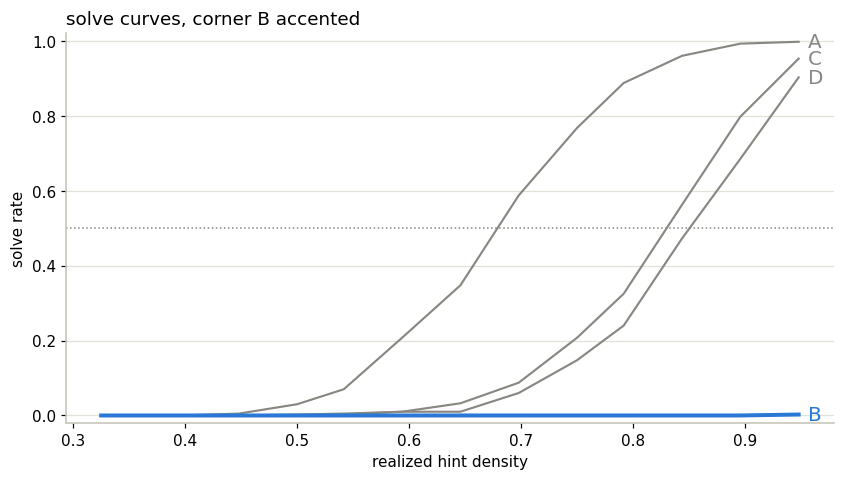

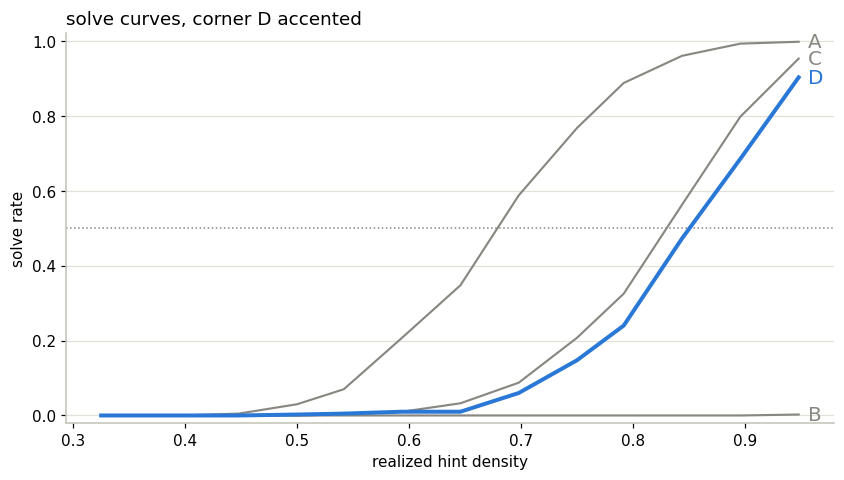

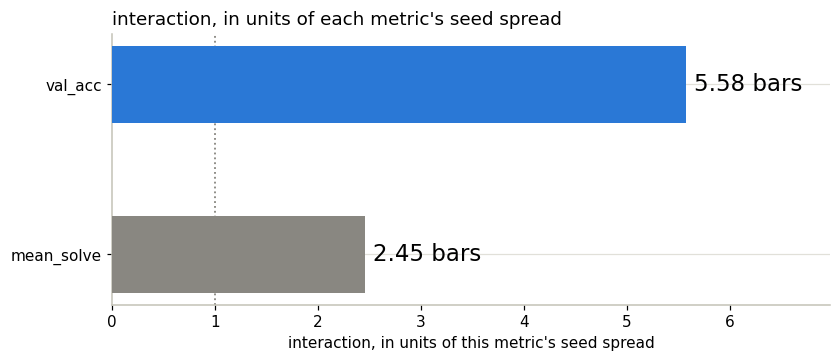

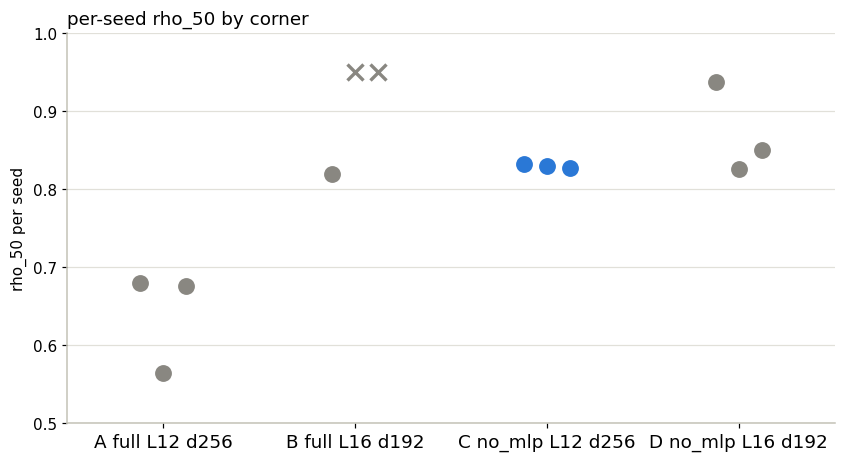

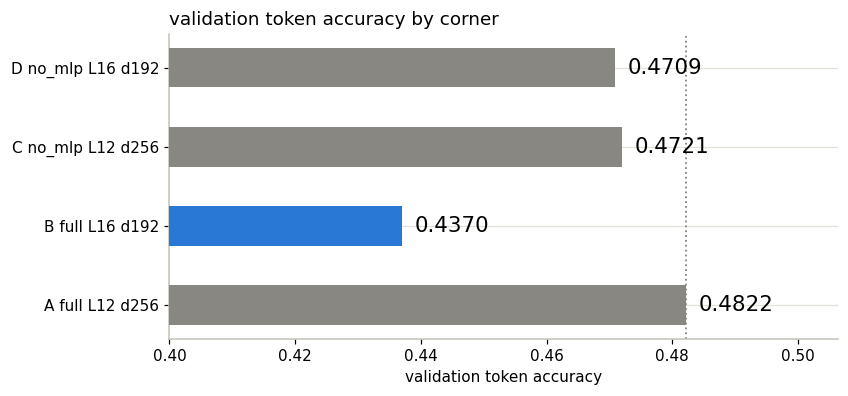

In [6]:
import matplotlib.pyplot as plt
from notebooks.make_stagem_deck import (draw_curves, draw_interaction,
                                        draw_per_seed, draw_acc)

for accent in ("B", "D"):
    fig, ax = plt.subplots(figsize=(9, 4.6))
    draw_curves(ax, S["keys"], S["curves"], accent)
    ax.set_title("solve curves, corner %s accented" % accent, loc="left")
    plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
draw_interaction(ax, S["ia_ms"], S["ia_acc"])
ax.set_title("interaction, in units of each metric's seed spread", loc="left")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.6))
draw_per_seed(ax, got)
ax.set_title("per-seed rho_50 by corner", loc="left")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
draw_acc(ax, got, got["A"]["acc"])
ax.set_title("validation token accuracy by corner", loc="left")
plt.show()

## 6. Against the previous best read of the same eval

Same grid, same 400 instances per bin, same frozen bars. **Stage F's numbers do
not move.** What moves is what they may be attributed to: on `rho_50` the MLP cut
alone already accounts for most of F's `+0.175`, while the shape cut alone is
*worse than either cut and worse than both together* — so F's gap is an
interaction, not a measurement of the attention-only cut.

In [7]:
print("stage F, as stagef_score printed it")
print("  rho_50     D - A  %+.3f" % F_GAP_RHO)
print("  mean_solve D - A  %+.4f" % F_GAP_MS)
print("  val_acc    D - A  %+.4f" % F_GAP_ACC)
print()
print("stage M, decomposing the same gap")
print("  dMLP   (C - A) rho_50 %+.3f   = %.0f%% of F's %+.3f"
      % (S["dMLP"]["rho_50"][0],
         100 * S["dMLP"]["rho_50"][0] / F_GAP_RHO, F_GAP_RHO))
print("  dSHAPE (B - A) rho_50 CENSORED -- 2 of 3 seeds never reach 0.5")
print("  so the single-axis attribution F invited cannot be made on rho_50,")
print("  and on the two never-censoring metrics it is sub-additive.")

stage F, as stagef_score printed it
  rho_50     D - A  +0.175
  mean_solve D - A  -0.2418
  val_acc    D - A  -0.0113

stage M, decomposing the same gap
  dMLP   (C - A) rho_50 +0.154   = 88% of F's +0.175
  dSHAPE (B - A) rho_50 CENSORED -- 2 of 3 seeds never reach 0.5
  so the single-axis attribution F invited cannot be made on rho_50,
  and on the two never-censoring metrics it is sub-additive.


## 7. What this does and does not establish

**Established, on three seeds per corner with the bars frozen before the run.**
At N=96, `full L=16 d192` does not train to a measurable `rho_50` on 2 of 3
seeds while `no_mlp L=16 d192` — the same depth, the same width, the same
budget, the same seeds — crosses on 3 of 3. At that shape the MLP is **actively
harmful**. Separately, at `L=12 d256` the MLP cut costs `+0.154` `rho_50`,
1.32 bars, consistent across all three metrics (M3 HELD).

**Not established, and registered as such in advance.** M0's headline. It asked
which single half is load-bearing, and the answer is that the question is
ill-posed at N=96: one half cannot be measured in isolation because the corner
that isolates it does not train. **Registered outcome (d) binds — the
one-cut-at-a-time ladder, which is what produced J2, KA and KB, cannot answer
this, and no single-factor statement from it generalizes to the other corner.**

**Still an N=48 claim, like every "smallest architecture" claim in this
programme.** M4 is a registration: nothing here may replace the N=48 standing
minimum (`no_mlp L=16 d192`, 2,504,890 trainable, `rho_50` 0.580, finding 53).
The grids and yardsticks differ and are never pooled.

**Three honest limits.**

* **The plateau has never been measured at N=96.** The N=48 criterion is train
  NLL 1.64; the N=96 band to date is 1.7456–1.8320 and no escape count is
  quoted anywhere above. Corner B's two censored seeds sit at 1.8783 and 1.8773,
  the two highest NLLs in the square — **consistent with an optimization failure
  rather than a capacity failure, and not distinguishable from one by this
  stage's data.** Telling those apart needs a schedule change at fixed
  architecture, which is a different experiment.
* **Three seeds cannot find a stuck seed** (finding 56). Corner B's 1-of-3
  crossing is, on three seeds, formally the same shape of evidence as finding
  51's seed story. It is called a corner-level result here because the two
  censored seeds agree with each other *and* with the accuracy and NLL ordering,
  not because 1-of-3 is by itself decisive.
* **The deck's page 11 trace is a ground-truth DD trace**, generated from the
  instance distribution — not a decode from any of these four checkpoints. It
  shows what the model is fed and asked to produce, which is what the
  tokenization page needs; it is not evidence about corner behaviour.

**What runs next, and why it is not here.** Under the brief of 2026-11-10 the
objective is the simplest or most analytically tractable architecture that still
learns direct deduction, so the live question is no longer N=96 transfer but
whether the attention-only family does the deduction at all — findings 27/28's
counterfactual audit has only ever been run on **full-architecture** checkpoints.
Stage Q runs it on the attention-only cell; stage P asks whether 16 layers can be
**one weight-tied operator iterated 16 times**. Finding 57 bears on that second
question directly: the attention-only family tolerates `L=16 d192`, where the
full family censors.